# Figure S5 — short test

Adult, BANC-DN, BANC-motor and ER controls; initial/final and hybrid neural sensitivities.

The saved tables and figures below come from a real short test and can be viewed directly on GitHub. To regenerate them, use the **Python (FlyControl)** kernel; see [setup and notebook index](README.md). Run cells from top to bottom. This notebook executes the same six stages as the command-line workflow, with reduced budgets and one training seed. It keeps every configured method. **These are software checks, not paper results.**

First execution downloads versioned public inputs. Neural assays and multi-stage maze prerequisites can still take substantial time; “short” refers to the training budget, not a seconds-long demonstration. Generated checkpoints, data and figures stay under `runs/`.

Choose a fresh `RUN_DIR` after code/configuration changes or for an independent restart. A completed run can be inspected with the “Inspect the smoke outputs” cell without retraining.

## Settings

Launch Jupyter from the repository root or `notebooks/`. Select the installed FlyControl kernel before running.

`DEVICE` defaults to CPU. To use a GPU, set it to an available device (for example `cuda:0`) or launch Jupyter with `FLYCONTROL_NOTEBOOK_DEVICE=cuda:0`. The saved execution records the device actually used.

In [1]:
from pathlib import Path
import sys
import os

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "src/flycontrol").is_dir()
)
sys.path.insert(0, str(ROOT / "notebooks"))
from notebook_utils import run_stage, show_outputs

CONFIG = 'banc-sensitivity'
RUN_DIR = ROOT / "runs/notebooks" / CONFIG
DEVICE = os.environ.get("FLYCONTROL_NOTEBOOK_DEVICE", "cpu")
WORKERS = 1
print(f"SMOKE TEST: {CONFIG} | {DEVICE} | {RUN_DIR.relative_to(ROOT)}")


SMOKE TEST: banc-sensitivity | cuda:0 | runs/notebooks/banc-sensitivity


## 1. Prepare

Download and checksum-verify public inputs, then resolve the reduced configuration. This cell always sets `--smoke`; all configured methods and the first training seed are retained.

In [2]:
run_stage("prepare", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: prepare** · 47.4 seconds · smoke test

Full execution log: `logs/notebook-prepare.log` within the run directory.

## 2. Train

Train fresh policies using the reduced budgets. This includes any prerequisites required by the selected experiment.

In [3]:
run_stage("train", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: train** · 140.8 seconds · smoke test

Full execution log: `logs/notebook-train.log` within the run directory.

## 3. Evaluate

Run the configured smoke evaluations in the real simulator, recording failures as well as successful episodes.

In [4]:
run_stage("evaluate", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: evaluate** · 2883.7 seconds · smoke test

Full execution log: `logs/notebook-evaluate.log` within the run directory.

## 4. Probe

Run the configured neural assays. Experiments without a neural assay record that explicitly. Short-trained policies can fail the required histories; read the recorded exclusions.

In [5]:
run_stage("probe", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: probe** · 78.4 seconds · smoke test

Full execution log: `logs/notebook-probe.log` within the run directory.

## 5. Analyze

Aggregate the generated numerical records. Smoke outputs do not support the manuscript’s statistical conclusions.

In [6]:
run_stage("analyze", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: analyze** · 20.1 seconds · smoke test

Full execution log: `logs/notebook-analyze.log` within the run directory.

## 6. Plot

Create diagnostic panels, numerical sources and editable PDF/SVG figures from this run.

In [7]:
run_stage("plot", CONFIG, RUN_DIR, DEVICE, WORKERS)

**Completed: plot** · 13.6 seconds · smoke test

Full execution log: `logs/notebook-plot.log` within the run directory.

## Inspect the smoke outputs

Check completion and effective settings, then inspect sample tables and up to three generated figures. All files remain available in `RUN_DIR`.

**SMOKE TEST — not paper results.**

,experiment,methods,training seeds
0,banc-sensitivity,"adult, banc_descending, banc_motor, er",[0]


Source/configuration SHA-256: `eaab77b7c7f8b5c50e7015c4c1c15e9ce272e2e432760c88fcc2e24c7a48ea9f`

,stage,completed,elapsed seconds
0,prepare,True,47.43
1,train,True,140.76
2,evaluate,True,2883.65
3,probe,True,78.37
4,analyze,True,20.11
5,plot,True,13.55


`analysis/seed_means.csv` (first eight rows)

...

`analysis/episodes.csv` (first eight rows)

,run_id,model,train_seed,eval_seed,case_id,family,protocol,full_duration,flip,numerical_failure,...,cycle_mean_200ms_settle_1_reached,cycle_mean_200ms_settle_1_time_s,cycle_mean_200ms_settle_1_restricted_time_s,cycle_mean_200ms_settle_2_reached,cycle_mean_200ms_settle_2_time_s,cycle_mean_200ms_settle_2_restricted_time_s,trace,trace_sha256,ramp_hysteresis_mm_s,slope_abs_mm_s2
0,adult_seed0,adult,0,101003,legacy_step_up_+0,step,legacy,True,False,False,...,False,NaN,2.00,False,NaN,2.00,/data2/ysy/github/FlyControl/runs/notebooks/ba...,fbfab9165da44bf246c86206bc4c44c1c8358964af44e4...,NaN,NaN
1,adult_seed0,adult,0,101003,legacy_step_down_+0,step,legacy,True,False,False,...,True,0.93,0.93,True,0.55,0.55,/data2/ysy/github/FlyControl/runs/notebooks/ba...,346f92baea33bc46e044bbab822b0be8312a0e3c7184ed...,NaN,NaN
2,adult_seed0,adult,0,101003,legacy_ramp_up,ramp,legacy,True,False,False,...,NaN,NaN,NaN,NaN,NaN,NaN,/data2/ysy/github/FlyControl/runs/notebooks/ba...,3b8d26d4c4636b5f60498ff3652b8e96ee1791517facb5...,3.001086,5.333333
3,adult_seed0,adult,0,101003,legacy_ramp_down,ramp,legacy,True,False,False,...,NaN,NaN,NaN,NaN,NaN,NaN,/data2/ysy/github/FlyControl/runs/notebooks/ba...,5f2af025cec9798beb49028d328a90357cde92d533c7b3...,2.107639,5.333333
4,adult_seed0,adult,0,101004,legacy_step_up_+0,step,legacy,True,False,False,...,False,NaN,2.00,False,NaN,2.00,/data2/ysy/github/FlyControl/runs/notebooks/ba...,b6dbf0121b06489e23a2c8b52ce11dc9d6d5b2580ec536...,NaN,NaN
5,adult_seed0,adult,0,101004,legacy_step_down_+0,step,legacy,True,False,False,...,True,0.93,0.93,True,0.55,0.55,/data2/ysy/github/FlyControl/runs/notebooks/ba...,e89c1b21247c5603671ba9ff538ee75124ec8862740bd5...,NaN,NaN
6,adult_seed0,adult,0,101004,legacy_ramp_up,ramp,legacy,True,False,False,...,NaN,NaN,NaN,NaN,NaN,NaN,/data2/ysy/github/FlyControl/runs/notebooks/ba...,4079a60be8faa9aaa60a72dda7b900017ebab054871119...,3.001086,5.333333
7,adult_seed0,adult,0,101004,legacy_ramp_down,ramp,legacy,True,False,False,...,NaN,NaN,NaN,NaN,NaN,NaN,/data2/ysy/github/FlyControl/runs/notebooks/ba...,08a5528973d97aadc27f563d851b5cac9e895094a13454...,2.107639,5.333333


`analysis/observed_counts.csv` (first eight rows)

,model,train_seed,case_id,full_duration,flip,numerical_failure,duration_s,zero_duration_terminal_events,partial_decision_intervals,tracking_mae,...,cycle_mean_200ms_tracking_observed_mean,cycle_mean_200ms_tracking_observed_mae,cycle_mean_200ms_tracking_observed_seconds,cycle_mean_200ms_tracking_missing_seconds,cycle_mean_200ms_settle_1_time_s,cycle_mean_200ms_settle_1_restricted_time_s,cycle_mean_200ms_settle_2_time_s,cycle_mean_200ms_settle_2_restricted_time_s,ramp_hysteresis_mm_s,slope_abs_mm_s2
0,adult,0,legacy_ramp_down,2,2,2,2,2,2,2,...,2,2,2,2,0,0,0,0,2,2
1,adult,0,legacy_ramp_up,2,2,2,2,2,2,2,...,2,2,2,2,0,0,0,0,2,2
2,adult,0,legacy_step_down_+0,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,0,0
3,adult,0,legacy_step_up_+0,2,2,2,2,2,2,2,...,2,2,2,2,0,2,0,2,0,0
4,banc_descending,0,legacy_ramp_down,2,2,2,2,2,2,2,...,2,2,2,2,0,0,0,0,2,2
5,banc_descending,0,legacy_ramp_up,2,2,2,2,2,2,2,...,2,2,2,2,0,0,0,0,2,2
6,banc_descending,0,legacy_step_down_+0,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,0,0
7,banc_descending,0,legacy_step_up_+0,2,2,2,2,2,2,2,...,2,2,2,2,0,2,0,2,0,0


`figures/paper/BANC_behavior_time_to_90_s.png`

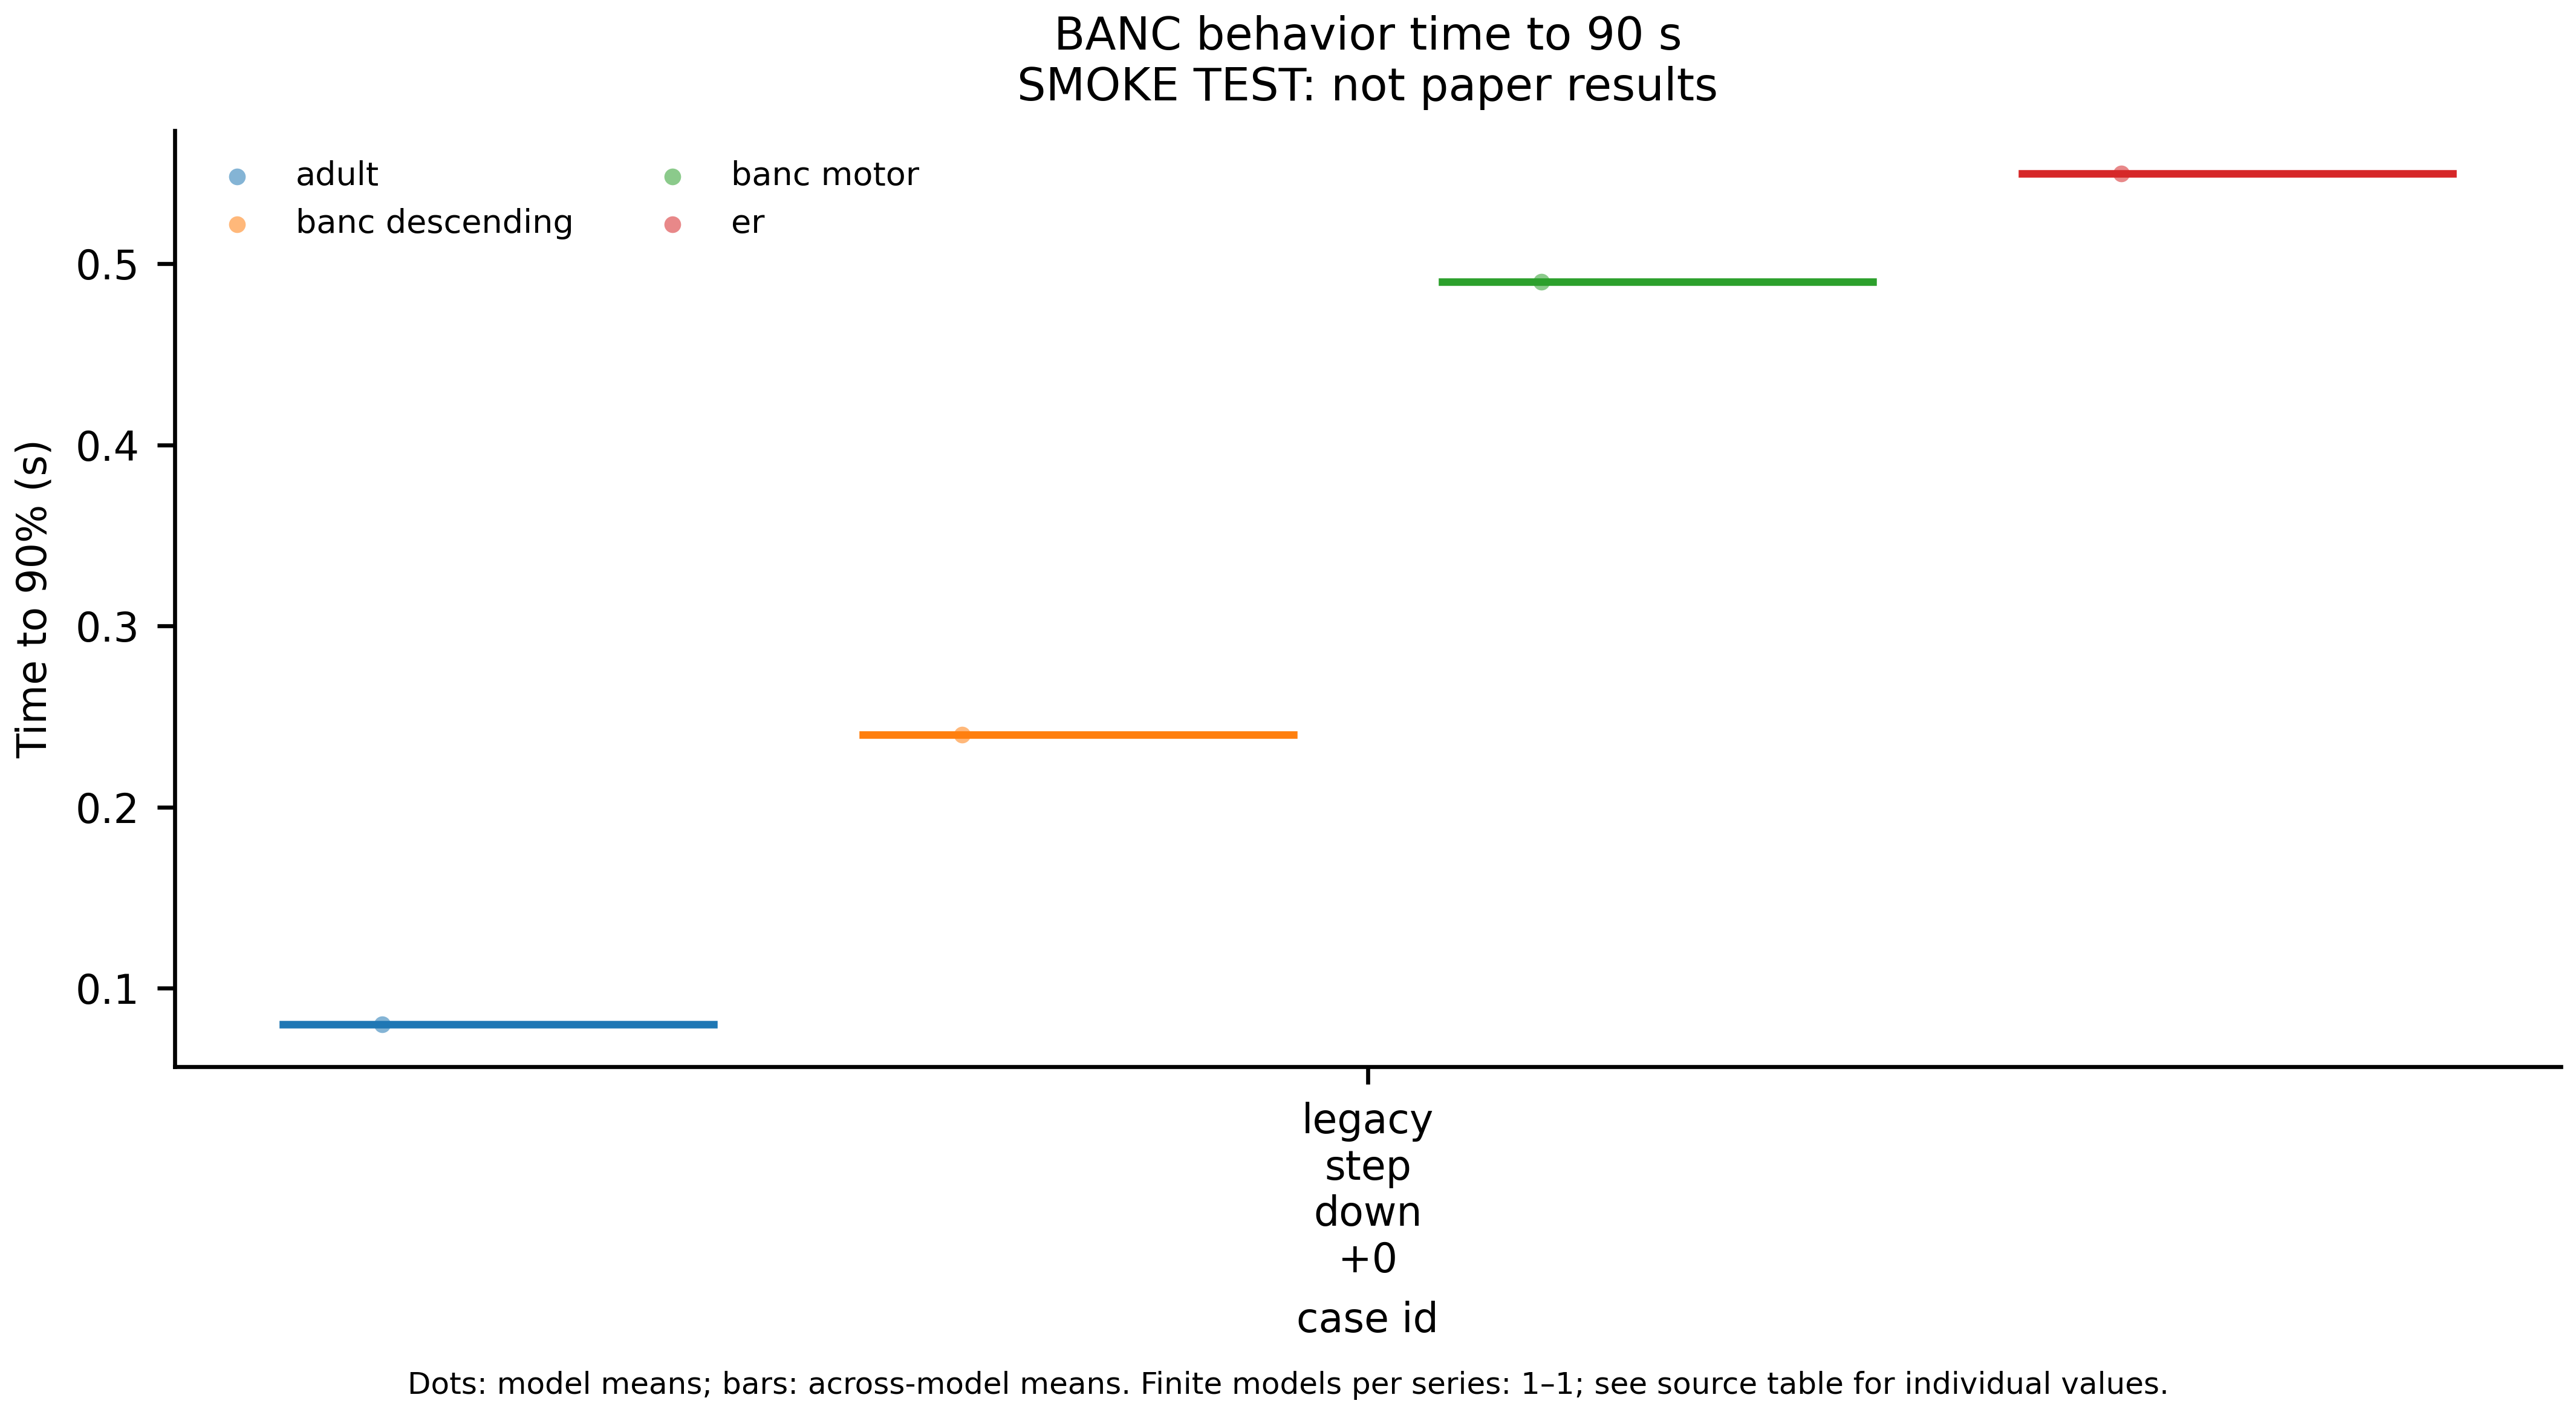

`figures/paper/BANC_behavior_tracking_mae.png`

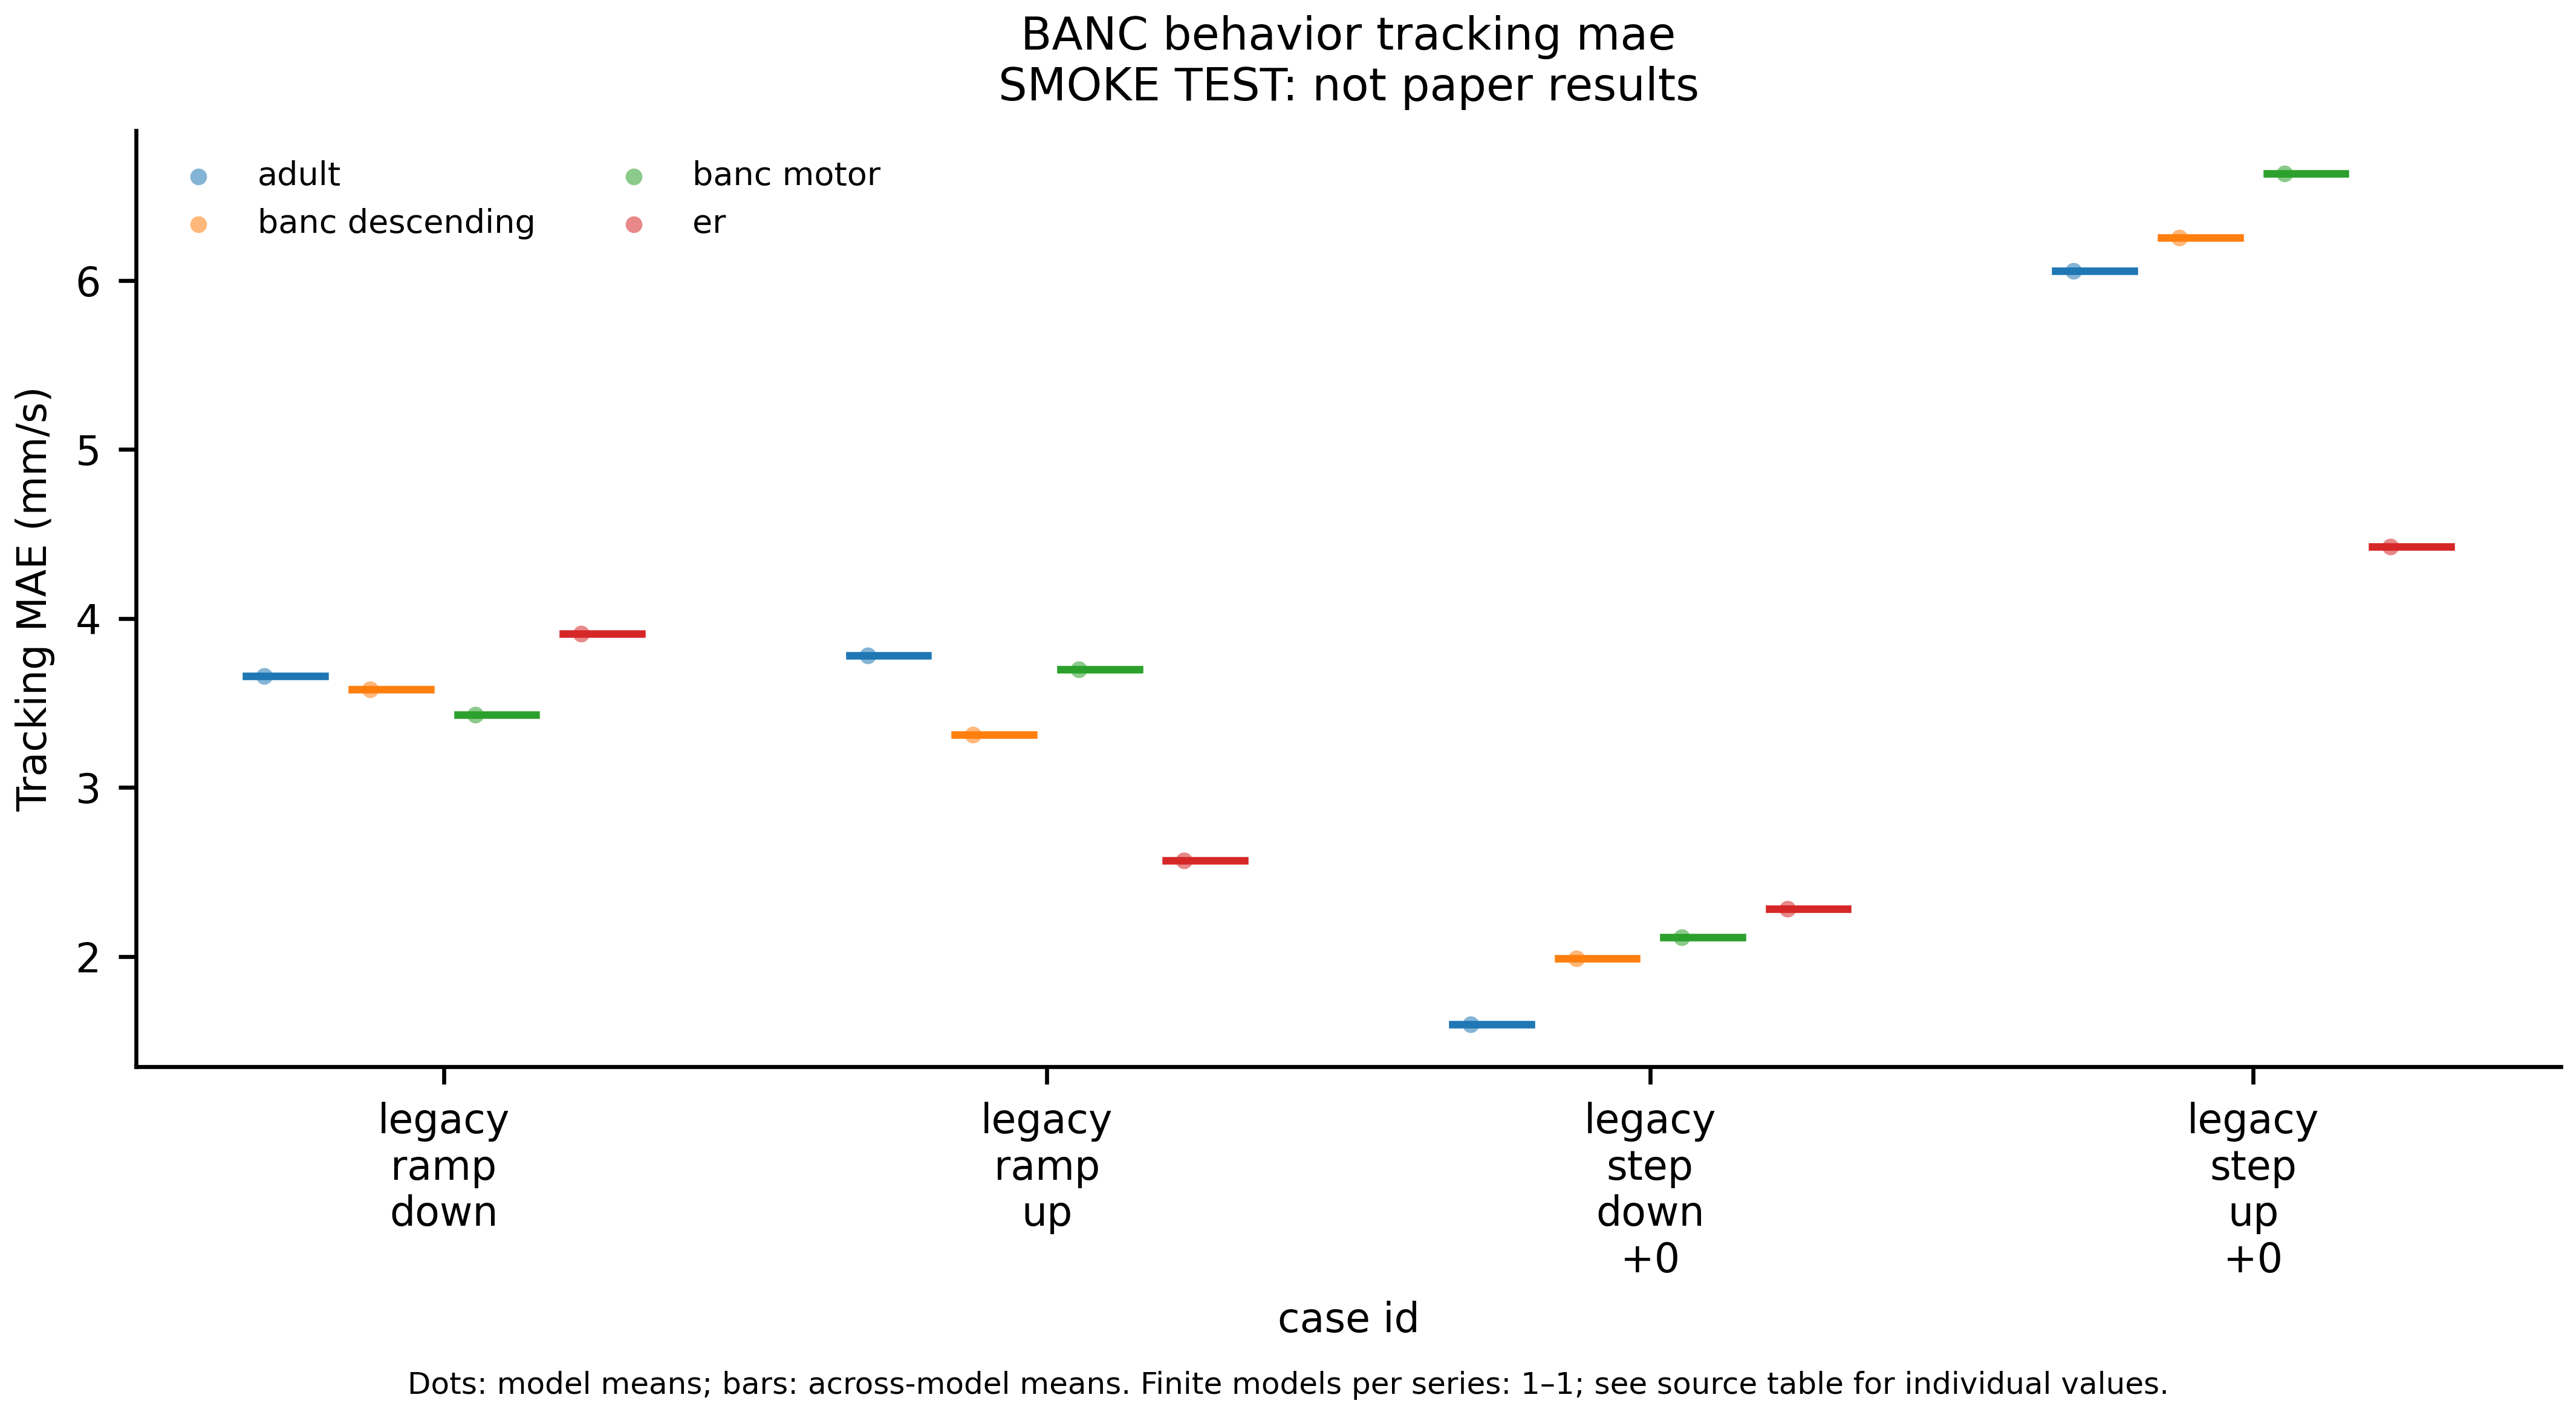

`figures/paper/BANC_behavior_tracking_rmse.png`

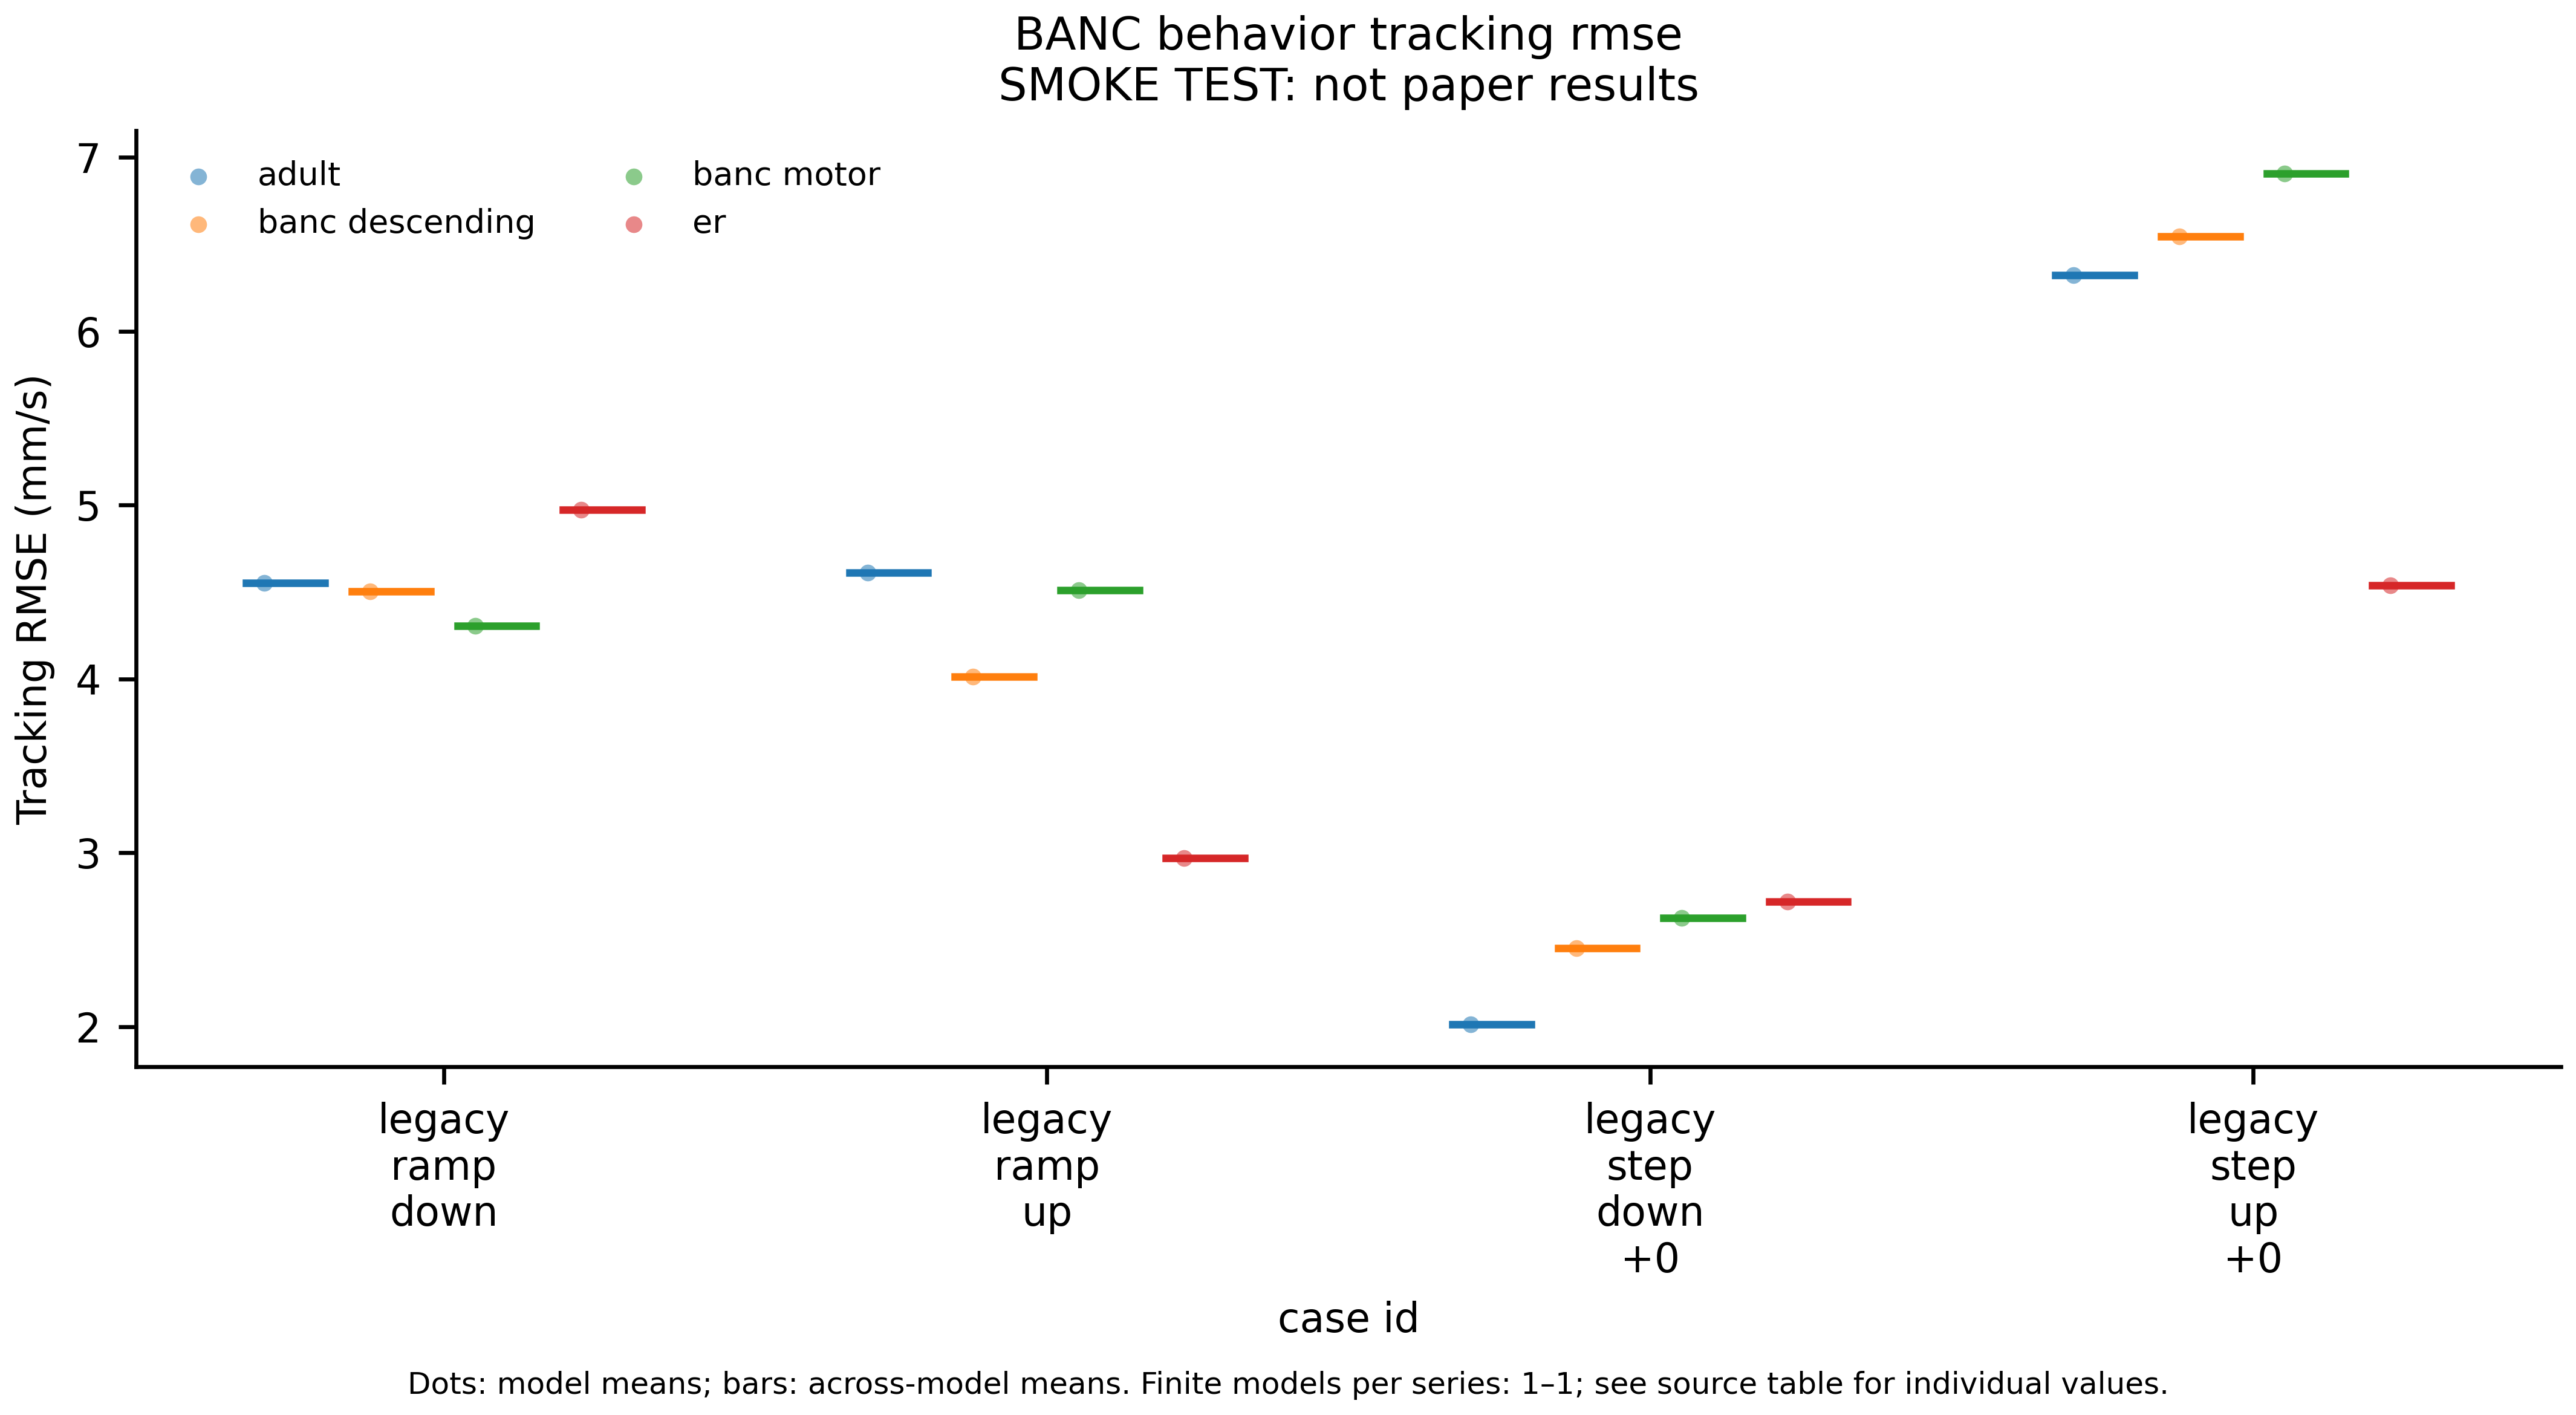

The complete numerical files and figures are saved in `RUN_DIR`. The tables and images displayed here are embedded in this notebook.

In [8]:
show_outputs(RUN_DIR)

## Full reproduction

Run this command in a terminal from the repository root, with the environment activated:

```bash
python scripts/S05_banc_sensitivity.py --run-dir runs/banc-sensitivity --device cuda:0 --workers 4
```

Equivalent command:

```bash
flycontrol run --config banc-sensitivity --run-dir runs/banc-sensitivity --device cuda:0 --workers 4
```

Use an available CUDA device, or `cpu`. Without `--smoke`, the script uses the complete fixed seed cohort, training budgets and condition grids. Keep full outputs in a separate run directory. These commands are documentation only; **Run All never launches the full campaign**.
